In [1]:
import pandas as pd
import numpy as np

In [2]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import accuracy_score

In [3]:
column_names = ["age", "workclass", "fnlwgt", "education", "education-num", "marital-status", "occupation", "relationship", "race", "sex", "capital-gain", "capital-loss", "hours-per-week", "native-country", "class"]

In [4]:
df = pd.read_csv("adult.data", names=column_names)

In [5]:
df

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,class
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32556,27,Private,257302,Assoc-acdm,12,Married-civ-spouse,Tech-support,Wife,White,Female,0,0,38,United-States,<=50K
32557,40,Private,154374,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,United-States,>50K
32558,58,Private,151910,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,Female,0,0,40,United-States,<=50K
32559,22,Private,201490,HS-grad,9,Never-married,Adm-clerical,Own-child,White,Male,0,0,20,United-States,<=50K


In [6]:
df.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,class
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [7]:
df.columns

Index(['age', 'workclass', 'fnlwgt', 'education', 'education-num',
       'marital-status', 'occupation', 'relationship', 'race', 'sex',
       'capital-gain', 'capital-loss', 'hours-per-week', 'native-country',
       'class'],
      dtype='object')

In [8]:
df.shape

(32561, 15)

In [9]:
df.dtypes

age                int64
workclass         object
fnlwgt             int64
education         object
education-num      int64
marital-status    object
occupation        object
relationship      object
race              object
sex               object
capital-gain       int64
capital-loss       int64
hours-per-week     int64
native-country    object
class             object
dtype: object

In [10]:
df.dtypes[df.dtypes == 'object']

workclass         object
education         object
marital-status    object
occupation        object
relationship      object
race              object
sex               object
native-country    object
class             object
dtype: object

In [11]:
df['workclass'].unique()

array([' State-gov', ' Self-emp-not-inc', ' Private', ' Federal-gov',
       ' Local-gov', ' ?', ' Self-emp-inc', ' Without-pay',
       ' Never-worked'], dtype=object)

In [12]:
d = {v: k for k, v in enumerate(set(df['workclass'].unique()))}

In [13]:
d

{' Without-pay': 0,
 ' ?': 1,
 ' Self-emp-inc': 2,
 ' Never-worked': 3,
 ' Local-gov': 4,
 ' Federal-gov': 5,
 ' State-gov': 6,
 ' Private': 7,
 ' Self-emp-not-inc': 8}

In [14]:
def generate_dict(data):
    my_dict = {v: k for k, v in enumerate(set(data))}
    return my_dict

In [15]:
generate_dict(df['education'].unique())

{' Assoc-acdm': 0,
 ' Doctorate': 1,
 ' 11th': 2,
 ' 12th': 3,
 ' Prof-school': 4,
 ' Bachelors': 5,
 ' 5th-6th': 6,
 ' 7th-8th': 7,
 ' 10th': 8,
 ' Masters': 9,
 ' 1st-4th': 10,
 ' 9th': 11,
 ' Preschool': 12,
 ' HS-grad': 13,
 ' Some-college': 14,
 ' Assoc-voc': 15}

In [16]:
obj_list = ["workclass", "education", "marital-status", "occupation", "relationship", "race", "sex", "class"]
obj_names = ["d_workclass", "d_education", "d_marital-status", "d_occupation", "d_relationship", "d_race", "d_sex", "d_class"]
for i,j in zip(obj_names,obj_list):
    print('{} = generate_dict(df["{}"].unique()'.format(i,j))

d_workclass = generate_dict(df["workclass"].unique()
d_education = generate_dict(df["education"].unique()
d_marital-status = generate_dict(df["marital-status"].unique()
d_occupation = generate_dict(df["occupation"].unique()
d_relationship = generate_dict(df["relationship"].unique()
d_race = generate_dict(df["race"].unique()
d_sex = generate_dict(df["sex"].unique()
d_class = generate_dict(df["class"].unique()


In [17]:
d_workclass = generate_dict(df["workclass"].unique())
d_education = generate_dict(df["education"].unique())
d_marital_status = generate_dict(df["marital-status"].unique())
d_occupation = generate_dict(df["occupation"].unique())
d_relationship = generate_dict(df["relationship"].unique())
d_race = generate_dict(df["race"].unique())
d_sex = generate_dict(df["sex"].unique())
d_native_country = generate_dict(df["native-country"].unique())
d_class = generate_dict(df["class"].unique())

In [18]:
d_workclass

{' Without-pay': 0,
 ' ?': 1,
 ' Self-emp-inc': 2,
 ' Never-worked': 3,
 ' Local-gov': 4,
 ' Federal-gov': 5,
 ' State-gov': 6,
 ' Private': 7,
 ' Self-emp-not-inc': 8}

In [19]:
df2 = df

In [20]:
df2.head(10)

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,class
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K
5,37,Private,284582,Masters,14,Married-civ-spouse,Exec-managerial,Wife,White,Female,0,0,40,United-States,<=50K
6,49,Private,160187,9th,5,Married-spouse-absent,Other-service,Not-in-family,Black,Female,0,0,16,Jamaica,<=50K
7,52,Self-emp-not-inc,209642,HS-grad,9,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,45,United-States,>50K
8,31,Private,45781,Masters,14,Never-married,Prof-specialty,Not-in-family,White,Female,14084,0,50,United-States,>50K
9,42,Private,159449,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,5178,0,40,United-States,>50K


In [21]:
df2["workclass"] = df2["workclass"].map(d_workclass)
df2["education"] = df2["education"].map(d_education)
df2["marital-status"] = df2["marital-status"].map(d_marital_status)
df2["occupation"] = df2["occupation"].map(d_occupation)
df2["relationship"] = df2["relationship"].map(d_relationship)
df2["race"] = df2["race"].map(d_race)
df2["sex"] = df2["sex"].map(d_sex)
df2["native-country"] = df2["native-country"].map(d_native_country)
df2["class"] = df2["class"].map(d_class)

In [22]:
df2.head(10)

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,class
0,39,6,77516,5,13,4,10,0,0,1,2174,0,40,19,0
1,50,8,83311,5,13,3,14,3,0,1,0,0,13,19,0
2,38,7,215646,13,9,2,5,0,0,1,0,0,40,19,0
3,53,7,234721,2,7,3,5,3,4,1,0,0,40,19,0
4,28,7,338409,5,13,3,13,4,4,0,0,0,40,5,0
5,37,7,284582,9,14,3,14,4,0,0,0,0,40,19,0
6,49,7,160187,11,5,5,8,0,4,0,0,0,16,7,0
7,52,8,209642,13,9,3,14,3,0,1,0,0,45,19,1
8,31,7,45781,9,14,4,13,0,0,0,14084,0,50,19,1
9,42,7,159449,5,13,3,14,3,0,1,5178,0,40,19,1


In [23]:
df2.to_csv("adult.csv")

In [24]:
df2.dtypes

age               int64
workclass         int64
fnlwgt            int64
education         int64
education-num     int64
marital-status    int64
occupation        int64
relationship      int64
race              int64
sex               int64
capital-gain      int64
capital-loss      int64
hours-per-week    int64
native-country    int64
class             int64
dtype: object

In [25]:
df_encoded = pd.get_dummies(
    df,
    columns=[
        'workclass',
        'education',
        'marital-status',
        'occupation',
        'relationship',
        'race',
        'sex',
        'native-country'
    ]
)

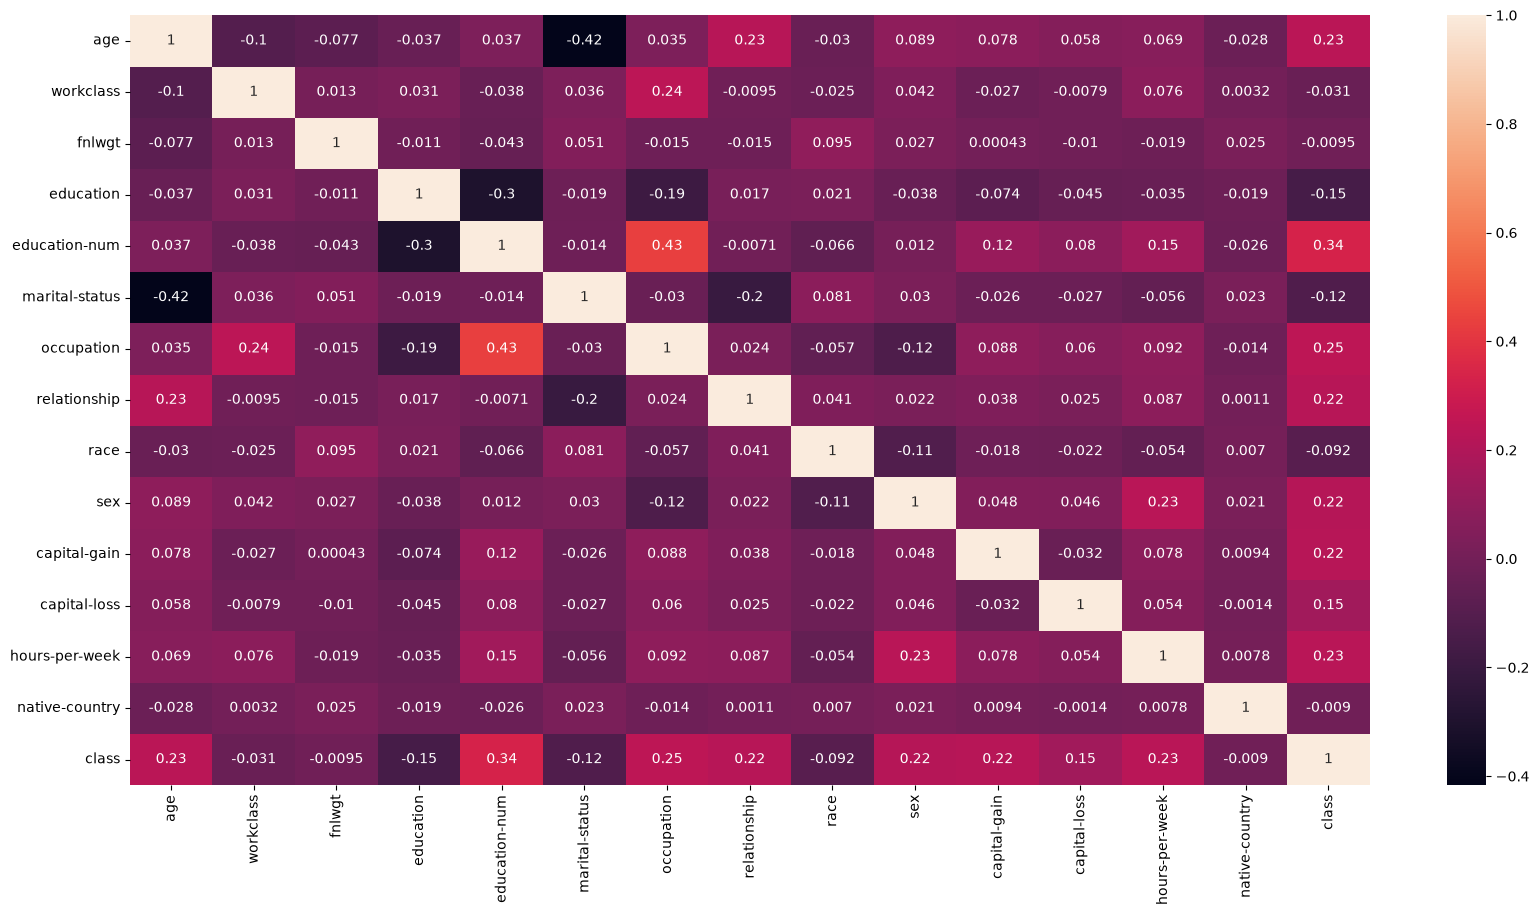

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

corr_mat = df2.corr()

plt.figure(figsize=(20,10))
sns.heatmap(corr_mat, annot=True)
plt.show()

<Figure size 2000x1000 with 0 Axes>

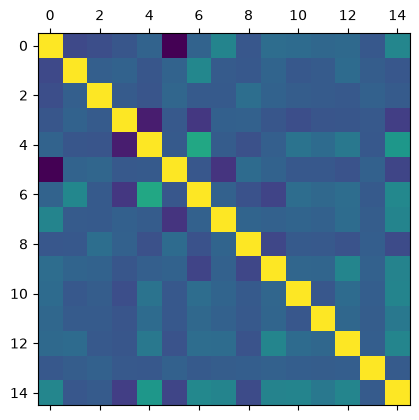

In [27]:
plt.figure(figsize=(20,10))
plt.matshow(corr_mat)
plt.show()

In [28]:
df['class'].value_counts()

class
0    24720
1     7841
Name: count, dtype: int64

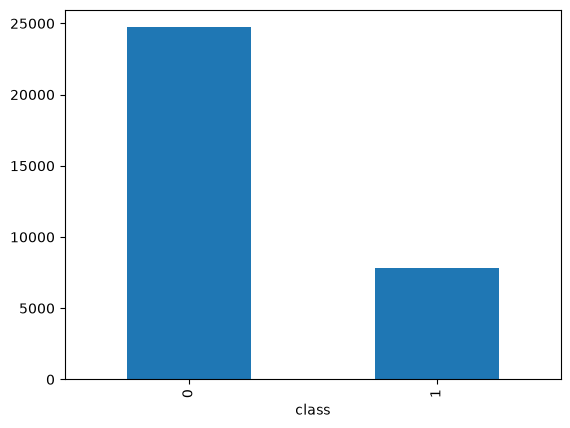

In [29]:
import matplotlib.pyplot as plt

df['class'].value_counts().plot(kind="bar")
plt.show()

In [30]:
df2.columns

Index(['age', 'workclass', 'fnlwgt', 'education', 'education-num',
       'marital-status', 'occupation', 'relationship', 'race', 'sex',
       'capital-gain', 'capital-loss', 'hours-per-week', 'native-country',
       'class'],
      dtype='object')

In [31]:
df2.shape

(32561, 15)

In [32]:
df2.iloc[:,0:14].columns

Index(['age', 'workclass', 'fnlwgt', 'education', 'education-num',
       'marital-status', 'occupation', 'relationship', 'race', 'sex',
       'capital-gain', 'capital-loss', 'hours-per-week', 'native-country'],
      dtype='object')

In [33]:
df2.iloc[:,14].name

'class'

In [34]:
X = df2.iloc[:,0:14].values
y = df2.iloc[:,14].values

In [35]:
x_train,x_test,y_train,y_test = train_test_split(X,y,test_size=0.33,random_state=42)

In [47]:
import warnings
warnings.filterwarnings('ignore')

In [48]:
print(x_train.shape)
print(y_train.shape)

(21815, 14)
(21815,)


In [49]:
logit = LogisticRegression()
logit.fit(x_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

In [50]:
logit.score(x_train, y_train)

0.8361677744671098

In [51]:
from sklearn.preprocessing import StandardScaler

sc = StandardScaler()

x_train = sc.fit_transform(x_train)
x_test = sc.transform(x_test)

In [52]:
from sklearn.linear_model import LogisticRegression

logit = LogisticRegression(max_iter=1000)
logit.fit(x_train, y_train)

print(logit.score(x_train, y_train))
print(logit.score(x_test, y_test))

0.8361677744671098
0.8364042434394193


In [53]:
import joblib

In [54]:
salary_logit_model = open("salary_logit_model.pkl","wb")
joblib.dump(logit, salary_logit_model)

In [55]:
salary_logit_model.close()

In [58]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

nv = MultinomialNB()
nv.fit(x_train, y_train)

,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None


In [61]:
nv.score(x_test,y_test)

0.768751163223525

In [62]:
salary_nv_model = open("salary_nv_model.pkl", "wb")
joblib.dump(nv, salary_nv_model)

In [63]:
salary_nv_model.close()

In [64]:
rf = RandomForestClassifier(n_estimators=100, max_depth=4)
rf.fit(x_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",4
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y_

In [65]:
rf.score(x_test,y_test)

0.8487809417457659

In [66]:
salary_rf_model = open("salary_rf_model.pkl", "wb")
joblib.dump(rf, salary_rf_model)

In [67]:
salary_rf_model.close()

In [68]:
cv_scores = cross_val_score(LogisticRegression(),X,y,cv=10)

In [69]:
print(cv_scores)

[0.79521032 0.80374693 0.79115479 0.78808354 0.79791155 0.80036855
 0.79084767 0.8022113  0.80159705 0.80251843]


In [70]:
print(np.mean(cv_scores))

0.7973650119681743


In [71]:
cv_scores2 = cross_val_score(RandomForestClassifier(n_estimators=100, max_depth=2),X,y,cv=10)

In [72]:
print(cv_scores2)

[0.79858766 0.79760442 0.80313268 0.8022113  0.80620393 0.80036855
 0.79637592 0.79883292 0.79668305 0.79361179]


In [73]:
print(np.mean(cv_scores2))

0.7993612227377962


In [74]:
cv_scores3 = cross_val_score(RandomForestClassifier(n_estimators=100, max_depth=4),X,y,cv=10)

In [75]:
print(cv_scores3)

[0.83942278 0.84889435 0.84981572 0.83937346 0.84889435 0.84797297
 0.84152334 0.85657248 0.85411548 0.84551597]


In [76]:
print(np.mean(cv_scores3))

0.8472100914379084


In [78]:
!pip install eli5

Defaulting to user installation because normal site-packages is not writeable

   ---------------------------------------- 0/2 [graphviz]
   ---------------------------------------- 0/2 [graphviz]
   -------------------- ------------------- 1/2 [eli5]
   -------------------- ------------------- 1/2 [eli5]
   -------------------- ------------------- 1/2 [eli5]
   ---------------------------------------- 2/2 [eli5]



In [79]:
import eli5

In [80]:
eli5.show_weights(logit, top=10)

In [81]:
df.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,class
0,39,6,77516,5,13,4,10,0,0,1,2174,0,40,19,0
1,50,8,83311,5,13,3,14,3,0,1,0,0,13,19,0
2,38,7,215646,13,9,2,5,0,0,1,0,0,40,19,0
3,53,7,234721,2,7,3,5,3,4,1,0,0,40,19,0
4,28,7,338409,5,13,3,13,4,4,0,0,0,40,5,0


In [82]:
d_class

{' <=50K': 0, ' >50K': 1}

In [83]:
df.columns

Index(['age', 'workclass', 'fnlwgt', 'education', 'education-num',
       'marital-status', 'occupation', 'relationship', 'race', 'sex',
       'capital-gain', 'capital-loss', 'hours-per-week', 'native-country',
       'class'],
      dtype='object')

In [84]:
feature_names = ['age', 'workclass', 'fnlwgt', 'education', 'education-num',
        'marital-status', 'occupation', 'relationship', 'race', 'sex',
        'capital-gain', 'capital-loss', 'hours-per-week', 'native-country']

In [85]:
class_names = ["<=50k", ">50k"]

In [86]:
eli5.show_weights(logit,feature_names=feature_names,target_names=class_names)

Weight?,Feature
+2.247,capital-gain
+0.756,education-num
+0.663,sex
+0.658,relationship
+0.436,age
+0.392,hours-per-week
+0.384,occupation
+0.260,capital-loss
+0.070,fnlwgt
+0.044,education


In [87]:
x_test[10]

array([0.35616438, 1.        , 0.15594056, 0.33333333, 0.8       ,
       0.66666667, 0.85714286, 0.        , 0.        , 1.        ,
       0.        , 0.        , 0.41836735, 0.46341463])

In [88]:
mysample = np.array(x_test[10]).reshape(1, -1)

In [89]:
logit.predict(mysample)

array([1], dtype=int64)

In [90]:
eli5.show_prediction(logit, x_test[10],feature_names=feature_names,target_names=class_names)

In [91]:
eli5.explain_weights(logit)

Weight?,Feature
+2.247,x10
+0.756,x4
+0.663,x9
+0.658,x7
+0.436,x0
+0.392,x12
+0.384,x6
+0.260,x11
+0.070,x2
+0.044,x3
